# Small Python Data-Processing App

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eyustarX/data-processing-app/blob/main/notebooks/data_analysis.ipynb)

This notebook demonstrates:
1. Loading a raw dataset with data quality issues.
2. Cleaning and sanitizing the data using custom Python functions.
3. High-performance numerical processing using **NumPy** arrays and vectorization.
4. Statistical summaries and visual representations.

## 0. Setup and Environment Verification

In [1]:
# Import core standard and scientific libraries
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

NumPy version: 2.5.4
Pandas version: 3.0.6


## 1. Load Raw Dataset
We load a raw sales dataset that includes duplicates, missing values (`NaN`), and invalid strings (`N/A`, negative counts).

In [2]:
# Determine project root path (works locally and in Colab)
data_path = Path("../data/raw_sales_data.csv")

# Fallback inline dataset for Google Colab if file is not mounted
if not data_path.exists():
    from io import StringIO
    raw_csv_data = """order_id,date,product,category,unit_price,quantity,discount_pct,city
1001,2024-01-05,Laptop,Electronics,1200,2,0.1,New York
1002,2024-01-06,Wireless Mouse,Electronics,25,10,0.05,Los Angeles
1003,2024-01-08,Desk Chair,Furniture,150,3,,Chicago
1004,2024-01-10,USB Cable,Electronics,12,-2,0,Houston
1005,2024-01-12,Mechanical Keyboard,Electronics,85,4,0.15,
1006,2024-01-15,Coffee Mug,Kitchen,15,5,0,New York
1007,2024-01-18,Gaming Monitor,Electronics,300,N/A,0.1,San Francisco
1008,2024-01-20,Office Desk,Furniture,,1,0.05,Austin
1009,2024-01-22,Desk Lamp,Furniture,45,3,0,Seattle
1010,2024-01-25,Water Bottle,Kitchen,20,8,0.2,Los Angeles
1001,2024-01-05,Laptop,Electronics,1200,2,0.1,New York
1011,2024-01-28,Headphones,Electronics,90,5,0.1,Chicago
1012,2024-01-30,Standing Desk,Furniture,400,2,,Houston"""
    raw_df = pd.read_csv(StringIO(raw_csv_data))
else:
    raw_df = pd.read_csv(data_path)

print(f"Raw dataset shape: {raw_df.shape}")
raw_df

Raw dataset shape: (13, 8)


,order_id,date,product,category,unit_price,quantity,discount_pct,city
0,1001,2024-01-05,Laptop,Electronics,1200.0,2.0,0.10,New York
1,1002,2024-01-06,Wireless Mouse,Electronics,25.0,10.0,0.05,Los Angeles
2,1003,2024-01-08,Desk Chair,Furniture,150.0,3.0,NaN,Chicago
3,1004,2024-01-10,USB Cable,Electronics,12.0,-2.0,0.00,Houston
4,1005,2024-01-12,Mechanical Keyboard,Electronics,85.0,4.0,0.15,NaN
5,1006,2024-01-15,Coffee Mug,Kitchen,15.0,5.0,0.00,New York
6,1007,2024-01-18,Gaming Monitor,Electronics,300.0,NaN,0.10,San Francisco
7,1008,2024-01-20,Office Desk,Furniture,NaN,1.0,0.05,Austin
8,1009,2024-01-22,Desk Lamp,Furniture,45.0,3.0,0.00,Seattle
9,1010,2024-01-25,Water Bottle,Kitchen,20.0,8.0,0.20,Los Angeles


## 2. Clean the Dataset Using Functions
We create dedicated functions to handle distinct data-quality issues:
- Removing duplicate entries
- Filtering invalid values and parsing numerical columns
- Imputing or dropping missing values

In [3]:
def remove_duplicates(df: pd.DataFrame, subset=None) -> pd.DataFrame:
    """Drop duplicate rows based on subset keys."""
    return df.drop_duplicates(subset=subset).reset_index(drop=True)

def sanitize_numbers(df: pd.DataFrame) -> pd.DataFrame:
    """Coerce string errors to NaN and discard invalid negative entries."""
    cleaned = df.copy()
    for col in ["unit_price", "quantity", "discount_pct"]:
        cleaned[col] = pd.to_numeric(cleaned[col], errors="coerce")
    cleaned = cleaned[(cleaned["quantity"] > 0) & (cleaned["unit_price"] > 0)]
    return cleaned.reset_index(drop=True)

def handle_nulls(df: pd.DataFrame) -> pd.DataFrame:
    """Impute sensible defaults for missing fields."""
    cleaned = df.copy()
    cleaned["discount_pct"] = cleaned["discount_pct"].fillna(0.0)
    cleaned["city"] = cleaned["city"].fillna("Unknown")
    cleaned = cleaned.dropna(subset=["order_id", "product", "unit_price", "quantity"])
    cleaned["order_id"] = cleaned["order_id"].astype(int)
    cleaned["quantity"] = cleaned["quantity"].astype(int)
    return cleaned.reset_index(drop=True)

def clean_dataset_pipeline(df: pd.DataFrame) -> pd.DataFrame:
    """Execute full cleaning workflow."""
    step1 = remove_duplicates(df, subset=["order_id"])
    step2 = sanitize_numbers(step1)
    return handle_nulls(step2)

cleaned_df = clean_dataset_pipeline(raw_df)
print(f"Cleaned dataset shape: {cleaned_df.shape}")
cleaned_df

Cleaned dataset shape: (9, 8)


,order_id,date,product,category,unit_price,quantity,discount_pct,city
0,1001,2024-01-05,Laptop,Electronics,1200.0,2,0.10,New York
1,1002,2024-01-06,Wireless Mouse,Electronics,25.0,10,0.05,Los Angeles
2,1003,2024-01-08,Desk Chair,Furniture,150.0,3,0.00,Chicago
3,1005,2024-01-12,Mechanical Keyboard,Electronics,85.0,4,0.15,Unknown
4,1006,2024-01-15,Coffee Mug,Kitchen,15.0,5,0.00,New York
5,1009,2024-01-22,Desk Lamp,Furniture,45.0,3,0.00,Seattle
6,1010,2024-01-25,Water Bottle,Kitchen,20.0,8,0.20,Los Angeles
7,1011,2024-01-28,Headphones,Electronics,90.0,5,0.10,Chicago
8,1012,2024-01-30,Standing Desk,Furniture,400.0,2,0.00,Houston


## 3. Data Processing with NumPy
We now leverage **NumPy** arrays for fast vectorized computations and statistical aggregations.

In [4]:
# Extract pure NumPy arrays
prices = cleaned_df["unit_price"].to_numpy(dtype=np.float64)
quantities = cleaned_df["quantity"].to_numpy(dtype=np.float64)
discounts = cleaned_df["discount_pct"].to_numpy(dtype=np.float64)

# Vectorized arithmetic with NumPy
gross_revenue = prices * quantities
discount_amount = gross_revenue * discounts
net_revenue = gross_revenue - discount_amount

# NumPy Min-Max Normalization (scaled between 0 and 1)
normalized_revenue = (net_revenue - np.min(net_revenue)) / (np.max(net_revenue) - np.min(net_revenue))

# NumPy Z-Score Standard Normalization (mean=0, std=1)
z_scores = (net_revenue - np.mean(net_revenue)) / np.std(net_revenue)

# Enrich DataFrame with NumPy results
processed_df = cleaned_df.copy()
processed_df["gross_revenue"] = gross_revenue
processed_df["net_revenue"] = net_revenue
processed_df["normalized_revenue"] = np.round(normalized_revenue, 3)
processed_df["revenue_z_score"] = np.round(z_scores, 3)
processed_df

,order_id,date,product,category,unit_price,quantity,discount_pct,city,gross_revenue,net_revenue,normalized_revenue,revenue_z_score
0,1001,2024-01-05,Laptop,Electronics,1200.0,2,0.10,New York,2400.0,2160.0,1.000,2.661
1,1002,2024-01-06,Wireless Mouse,Electronics,25.0,10,0.05,Los Angeles,250.0,237.5,0.078,-0.458
2,1003,2024-01-08,Desk Chair,Furniture,150.0,3,0.00,Chicago,450.0,450.0,0.180,-0.113
3,1005,2024-01-12,Mechanical Keyboard,Electronics,85.0,4,0.15,Unknown,340.0,289.0,0.103,-0.375
4,1006,2024-01-15,Coffee Mug,Kitchen,15.0,5,0.00,New York,75.0,75.0,0.000,-0.722
5,1009,2024-01-22,Desk Lamp,Furniture,45.0,3,0.00,Seattle,135.0,135.0,0.029,-0.625
6,1010,2024-01-25,Water Bottle,Kitchen,20.0,8,0.20,Los Angeles,160.0,128.0,0.025,-0.636
7,1011,2024-01-28,Headphones,Electronics,90.0,5,0.10,Chicago,450.0,405.0,0.158,-0.186
8,1012,2024-01-30,Standing Desk,Furniture,400.0,2,0.00,Houston,800.0,800.0,0.348,0.454


## 4. NumPy Statistical Computations

In [5]:
print("=== Net Revenue Statistics via NumPy ===")
print(f"Total Revenue : ${np.sum(net_revenue):,.2f}")
print(f"Mean Revenue  : ${np.mean(net_revenue):,.2f}")
print(f"Median Revenue: ${np.median(net_revenue):,.2f}")
print(f"Standard Dev  : ${np.std(net_revenue):,.2f}")
print(f"Minimum       : ${np.min(net_revenue):,.2f}")
print(f"Maximum       : ${np.max(net_revenue):,.2f}")
print(f"25th & 75th % : ${np.percentile(net_revenue, 25):,.2f} / ${np.percentile(net_revenue, 75):,.2f}")

=== Net Revenue Statistics via NumPy ===
Total Revenue : $4,679.50
Mean Revenue  : $519.94
Median Revenue: $289.00
Standard Dev  : $616.37
Minimum       : $75.00
Maximum       : $2,160.00
25th & 75th % : $135.00 / $450.00


## 5. Visualizations

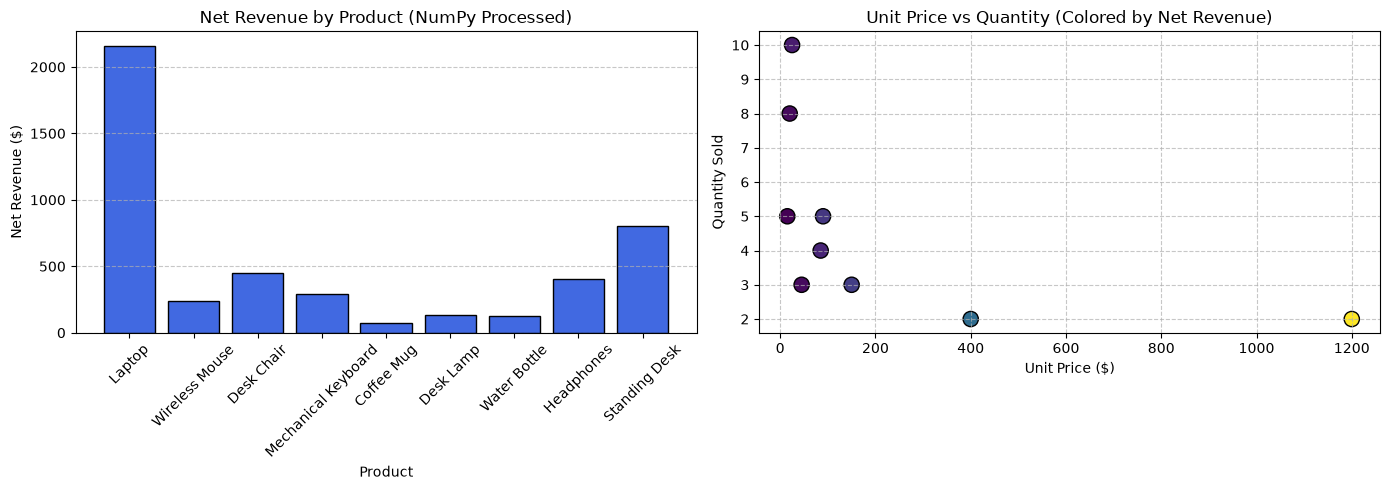

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# 1. Bar Chart: Net Revenue by Product
ax[0].bar(processed_df["product"], processed_df["net_revenue"], color="royalblue", edgecolor="black")
ax[0].set_title("Net Revenue by Product (NumPy Processed)")
ax[0].set_xlabel("Product")
ax[0].set_ylabel("Net Revenue ($)")
ax[0].tick_params(axis="x", rotation=45)
ax[0].grid(axis="y", linestyle="--", alpha=0.7)

# 2. Scatter Plot: Price vs Quantity
ax[1].scatter(processed_df["unit_price"], processed_df["quantity"], c=processed_df["net_revenue"], cmap="viridis", s=120, edgecolors="black")
ax[1].set_title("Unit Price vs Quantity (Colored by Net Revenue)")
ax[1].set_xlabel("Unit Price ($)")
ax[1].set_ylabel("Quantity Sold")
ax[1].grid(True, linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()